# Sample-level cohort analysis with MrVI — latent hierarchy, donor distances, DA and DE

[MrVI](https://doi.org/10.1038/s41592-025-02808-x) (Boyeau, Hong *et al.*, *Nat Methods*
2025) is a hierarchical variational model built for **multi-sample** scRNA-seq cohorts:
every cell gets a sample-*unaware* latent `u` (its cell state, independent of which
donor/sample it came from) and a sample-*aware* latent `z`, obtained from `u` through a
small attention block conditioned on the cell's sample. Because `z` can be re-encoded
under *any* sample (not only the cell's own, i.e. counterfactually), MrVI gives three
sample-level analyses "for free", without ever subsetting the data per sample:

- **Sample-sample distances**, local to a group of cells (e.g. per cell type) — "how
  different do donor A and donor B look, as seen through monocytes vs through T cells?"
- **Differential abundance (DA)** — how well a cell's own state (`u`) is explained by
  each sample / sample-covariate value's aggregated posterior.
- **Differential expression (DE)** — a per-cell multivariate regression of the
  counterfactual `z`-shift on sample covariates, decoded back to gene log2 fold-changes.

`ov.vi.MRVI` is omicverse's own PyTorch port of MrVI (against scvi-tools 1.5.2's torch
backend) — **no scvi-tools / jax dependency**. `ov.single.mrvi` wraps model
construction + training when you only need the `u` embedding; here we use
`ov.vi.MRVI` directly for the full sample-level toolkit.

**Data**: Wilk *et al.*, 2020, *Nat Med* — a Seq-Well scRNA-seq atlas of peripheral
blood mononuclear cells (PBMCs) from 13 donors (7 hospitalised COVID-19, 6 healthy),
downloaded from its [CZ CELLxGENE Discover collection]
(https://cellxgene.cziscience.com/collections/a72afd53-ab92-4511-88da-252fb0e26b9a).
We use `sample_key='donor_id'` and `disease` (`'COVID-19'` vs `'normal'`) as the sample
covariate for DA/DE — the same setup used to validate `ov.vi.MRVI` against scvi-tools
(`benchmarks/vi/results_mrvi.md`).

In [1]:
import omicverse as ov
import anndata as ad
import numpy as np
import pandas as pd
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 2
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0
    • [CUDA 1] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. Data: Wilk 2020 COVID-19 PBMC cohort

Downloaded directly from CZ CELLxGENE Discover (public, no API key). The processed
object already carries raw counts in `.raw.X`, log-normalised values in `.X`, and the
authors' own per-cell interferon-stimulated-gene and HLA-class-II module scores
(`obs['IFN1']`, `obs['HLA1']`), which we use later as an independent check on our own
DE result.

In [2]:
url = "https://datasets.cellxgene.cziscience.com/8d7fad46-2f37-4aa0-ac9d-babbc36efb6f.h5ad"
adata = ov.datasets.get_adata(url, filename='wilk2020_covid_pbmc.h5ad')
adata.obs['cell_type'] = adata.obs['cell.type.coarse'].astype(str).astype('category')
adata

⚠️ File ./data/wilk2020_covid_pbmc.h5ad already exists
 Loading data from ./data/wilk2020_covid_pbmc.h5ad


✅ Successfully loaded: 44721 cells × 24505 genes


AnnData object with n_obs × n_vars = 44721 × 24505
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.rps', 'percent.rpl', 'percent.rrna', 'nCount_SCT', 'nFeature_SCT', 'seurat_clusters', 'singler', 'cell.type.fine', 'cell.type.coarse', 'IFN1', 'HLA1', 'donor_id', 'DPS', 'DTF', 'Admission', 'Ventilated', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_pca', 'X_umap'
    layers: None (

In [3]:
pd.crosstab(adata.obs['donor_id'], adata.obs['disease'])

disease   COVID-19  normal
donor_id                  
C1            8362       0
C2            1735       0
C3            6545       0
C4            3688       0
C5            2507       0
C6            1893       0
C7            3364       0
H1               0    2100
H2               0    1941
H3               0    2306
H4               0    5136
H5               0    3146
H6               0    1998

13 donors, 44,721 cells total, cleanly split into 7 COVID-19 donors (`C1`-`C7`) and 6
healthy donors (`H1`-`H6`). We subsample per donor below to keep this tutorial's GPU
time short while preserving every donor's representation (MrVI's sample-level analyses
need every sample present).

In [4]:
adata.layers['counts'] = adata.raw.X.copy()
adata.X = adata.layers['counts'].copy()
adata = ov.pp.qc(adata, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 200}, doublets=False)
adata.shape

🖥️ Using CPU mode for QC...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 0 ⚠️               │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 0 ⚠️               │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 0 ⚠️               │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴────────────────────┘

   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range 

   ✓ Final filtering: 0 cells, 0 genes removed

📊 Step 4: Doublet detection disabled

╭─ SUMMARY: qc ──────────────────────────────────────────────────────╮
│  Duration: 1.1493s                                                 │
│  Shape:    44,721 x 24,505 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ cell_complexity (float)                              │
│           │ ✚ detected_genes (int)                                 │
│           │ ✚ hb_perc (float)                                      │
│           │ ✚ mito_perc (float)                                    │
│           │ ✚ nUMIs (float)                                        │
│           │ ✚ n_counts (float)                                     │
│           │ ✚ n_genes (int)                                 

(44107, 24505)

In [5]:
frac = min(1.0, 12_000 / adata.n_obs)
keep = adata.obs.groupby('donor_id', group_keys=False).apply(lambda d: d.sample(frac=frac, random_state=0))
adata = adata[keep.index].copy()
adata.obs['donor_id'].value_counts()

donor_id
C1    2273
C3    1775
H4    1397
C4    1003
C7     914
H5     856
C5     682
H3     627
H1     571
H6     543
H2     527
C2     470
C6     362
Name: count, dtype: int64

### Highly variable genes

2,000 HVGs by Pearson residuals (`ov.pp.preprocess`). The model trains on raw counts
(`layer='counts'`) restricted to `var['highly_variable_features']` via its own `genes=`
argument — the AnnData itself is not subset, so the full gene set stays available for
QC / plotting.

In [6]:
adata.X = adata.layers['counts'].copy()
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', n_HVGs=2000)
adata.var['highly_variable_features'].sum()

🔍 [2026-11-15 04:57:50] Running preprocessing in 'cpu' mode...
Begin robust gene identification


    After filtration, 24400/24505 genes are kept.
    Among 24400 genes, 20270 genes are robust.


✅ Robust gene identification completed successfully.
Begin size normalization: shiftlog and HVGs selection pearson

🔍 Count Normalization:
   Target sum: 500000.0
   Exclude highly expressed: True
   Max fraction threshold: 0.2
   ⚠️ Excluding 9 highly-expressed genes from normalization computation
   Excluded genes: ['ENSG00000240247', 'ENSG00000210082', 'ENSG00000211679', 'ENSG00000211899', 'ENSG00000244734', 'ENSG00000211897', 'ENSG00000211895', 'ENSG00000211896', 'ENSG00000211893']

✅ Count Normalization Completed Successfully!
   ✓ Processed: 12,000 cells × 20,270 genes
   ✓ Runtime: 0.07s

🔍 Highly Variable Genes Selection (Experimental):
   Method: pearson_residuals
   Target genes: 2,000
   Theta (overdispersion): 100



✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 20,270 total (9.9%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 0.43 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ────────────────────

np.int64(2000)

In [7]:
adata.X = adata.layers['counts'].copy()  # storage='disk' (AnnDataOOM) skips layers, so X must hold counts
adata.X.sort_indices(); adata.layers['counts'].sort_indices()  # anndata-rs needs sorted minor indices
del adata.obsm['X_pca'], adata.obsm['X_umap']
adata.write_h5ad('wilk2020_prepped.h5ad')

## 2. Train `ov.vi.MRVI`

`sample_key='donor_id'` is what MrVI's hierarchy and every downstream analysis below
conditions on. `disease` is *not* passed as `labels_key` — it is used only afterwards,
as a `sample_cov_keys=` covariate for DA/DE (passing it as `labels_key` would instead
override the `u` mixture prior to one component per label, which can destabilise
training, see `benchmarks/vi/results_mrvi.md`).

In [8]:
model = ov.vi.MRVI(adata, sample_key='donor_id', layer='counts', genes='highly_variable_features',
                    n_latent=20, n_latent_u=8, encoder_n_hidden=128, encoder_n_layers=2,
                    u_prior_mixture_k=12, seed=0)
model

MRVI(n_obs=12000, n_vars=2000, n_batch=1, n_labels=1, layer='counts', trained=False)

`ov.vi.MRVI.train()` defaults `cuda_graph` to `False` (CUDA-graph capture of MrVI's
step currently fails without a graceful eager fallback, see the model's own
docstring) — everything else is plain PyTorch on the GPU, no Lightning / scvi-tools.
`ov.vi.MemoryMonitor` reports wall time, host RSS and GPU memory of the block.

In [9]:
with ov.vi.MemoryMonitor() as mon:
    model.train(max_epochs=120, batch_size=256, device='cuda', seed=0, check_val_every_n_epoch=5,
                plan_kwargs=dict(lr=2e-3, eps=1e-8, weight_decay=1e-8, n_epochs_kl_warmup=20))
mon

Training:   0%|          | 0/120 [00:00<?, ?epoch/s]

MemoryMonitor(wall 31.3 s, RSS 2.48 -> peak 2.91 GB (+0.43), GPU used peak 0.92 GB)

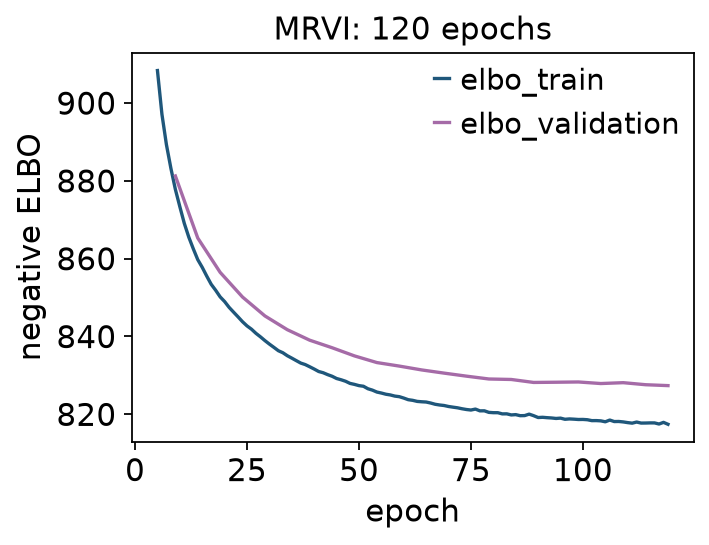

In [10]:
ov.vi.plot_history(model, skip_first=5);

Both the training and validation ELBO drop together and flatten without the
validation curve turning back up — not overfitting on this 12,000-cell / 120-epoch
run.

## 3. Latent hierarchy: `u` (sample-unaware) vs `z` (sample-aware)

`u` is what the `u`-encoder sees cell state as, *before* any sample-specific attention —
it should separate cells mainly by cell type, with donors and disease status mixed
within each type. `z = z_base(u, own sample) + eps` is what the decoder actually
reconstructs counts from, so it also carries the sample-specific shift — the
representation the counterfactual sample-distance, DA and DE analyses below all
operate on.

In [11]:
u = model.get_latent_representation()
z = model.get_latent_representation(give_z=True)
adata.obsm['X_mrvi_u'] = u
adata.obsm['X_mrvi_z'] = z

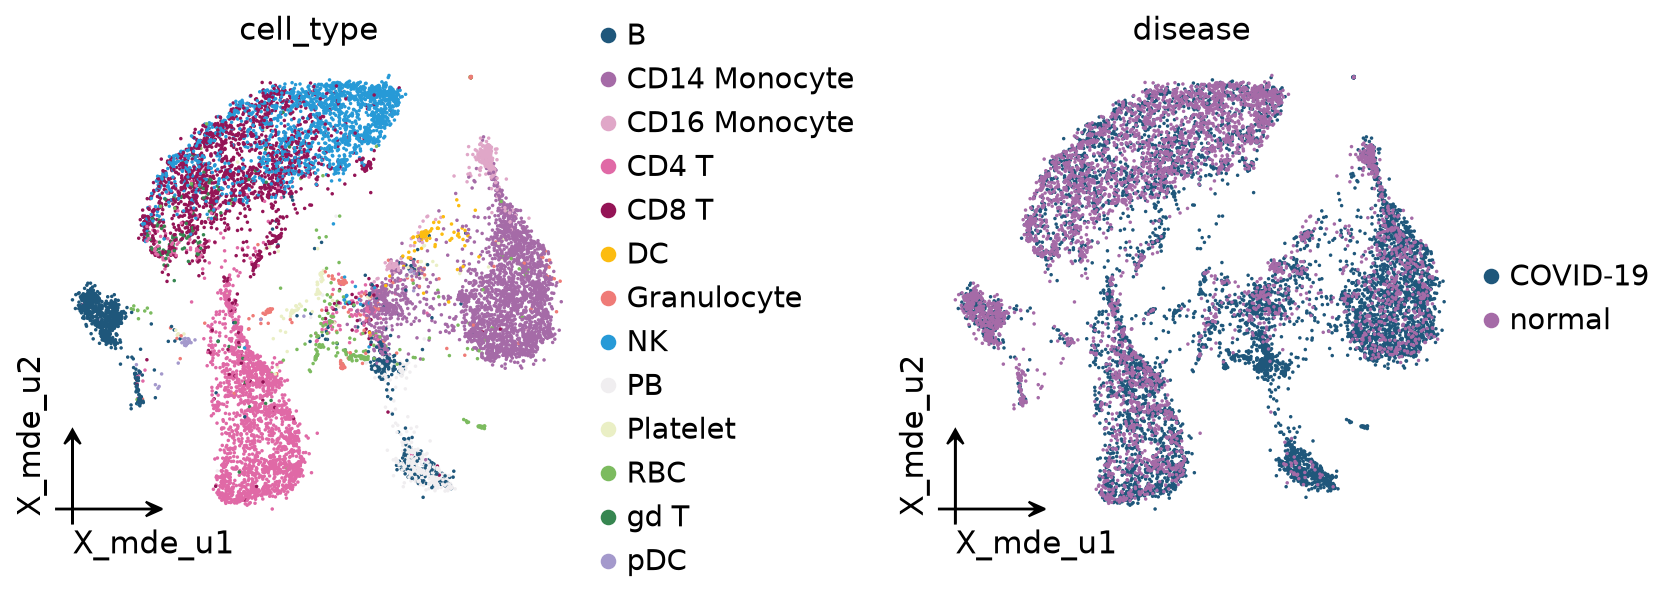

In [12]:
adata.obsm['X_mde_u'] = ov.vi.mde(u)
adata.obsm['X_mde_z'] = ov.vi.mde(z)
ov.pl.embedding(adata, basis='X_mde_u', color=['cell_type', 'disease'], frameon='small', wspace=0.5)

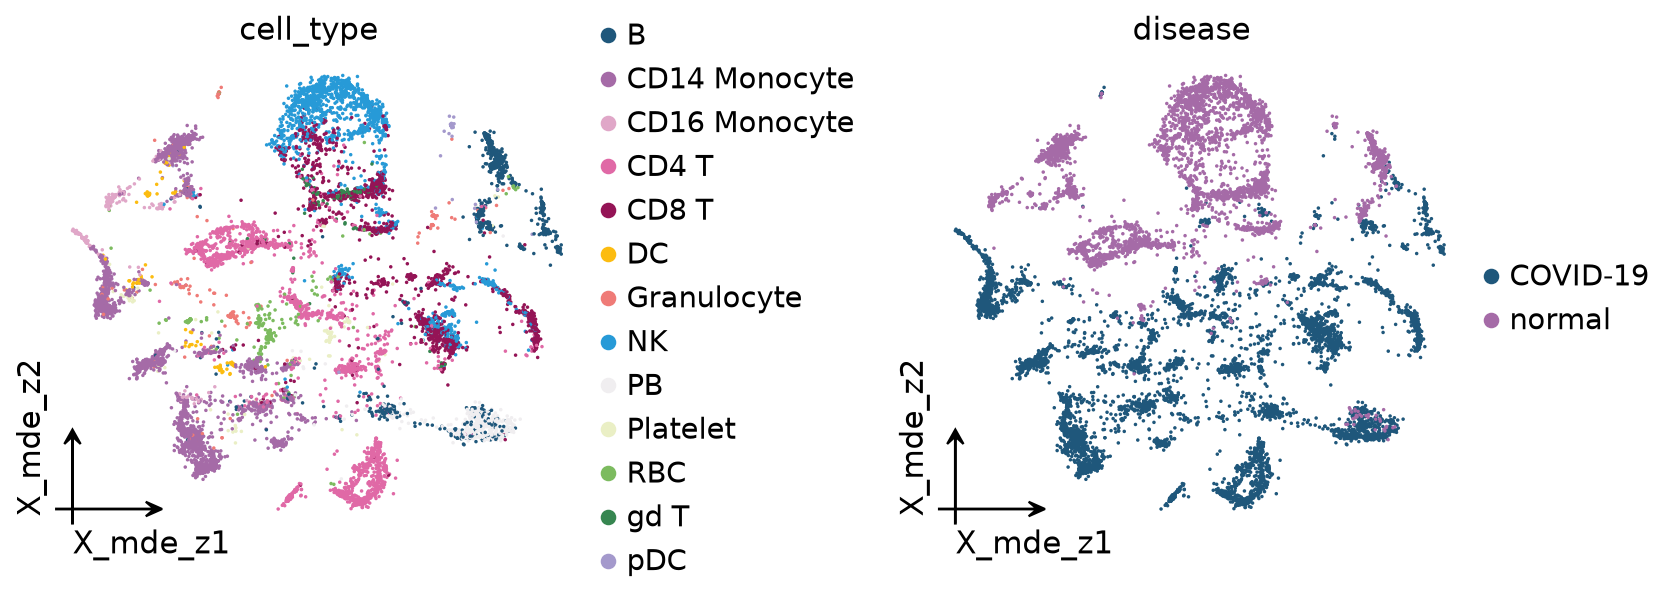

In [13]:
ov.pl.embedding(adata, basis='X_mde_z', color=['cell_type', 'disease'], frameon='small', wspace=0.5)

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
km = KMeans(adata.obs['cell_type'].nunique(), n_init=5, random_state=0).fit_predict(u)
adjusted_rand_score(adata.obs['cell_type'], km)

0.5370670526396759

KMeans on `u` alone recovers the authors' cell-type annotation at ARI ≈ 0.54 with no
batch/donor/disease information given to the clustering — `u` is behaving as the
sample-unaware cell-state code it is meant to be: in its MDE, cells group tightly by
`cell_type` with donors and disease fully mixed inside each type. `z`, in contrast,
splits almost cleanly into two disease-defined halves that each still show the same
internal cell-type substructure — the attention block has learned a shift so
disease-correlated that it dominates the 2-D projection, which is exactly the
sample-conditioned signal the counterfactual distance, DA and DE analyses below are
built to quantify.

## 4. Cell-type-specific sample (donor) distance matrices

`get_local_sample_distances(groupby='cell_type')` gives, for every cell type, the
average pairwise distance between donors *as seen through that cell type's cells*
(each cell's counterfactual `z` under every donor in turn). We annotate donors by
disease status and look at classical monocytes — the cell type Wilk *et al.* (2020)
found most transcriptionally perturbed by COVID-19 — against CD4⁺ T cells.

In [15]:
dist = model.get_local_sample_distances(batch_size=512, groupby='cell_type', keep_cell=False)
dist['sample_order']

['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'H1', 'H2', 'H3', 'H4', 'H5', 'H6']

In [16]:
import seaborn as sns
donor_disease = adata.obs.drop_duplicates('donor_id').set_index('donor_id')['disease']
def plot_sample_dist(ct):
    mat = pd.DataFrame(dist['groups']['cell_type'][ct], index=dist['sample_order'], columns=dist['sample_order'])
    colors = donor_disease.loc[mat.index].map({'COVID-19': '#d62728', 'normal': '#1f77b4'})
    return sns.clustermap(mat, row_colors=colors, col_colors=colors, cmap='viridis', figsize=(4.5, 4.5))

Text(0.5, 1.02, 'CD14 Monocyte donor distances (u-space)')

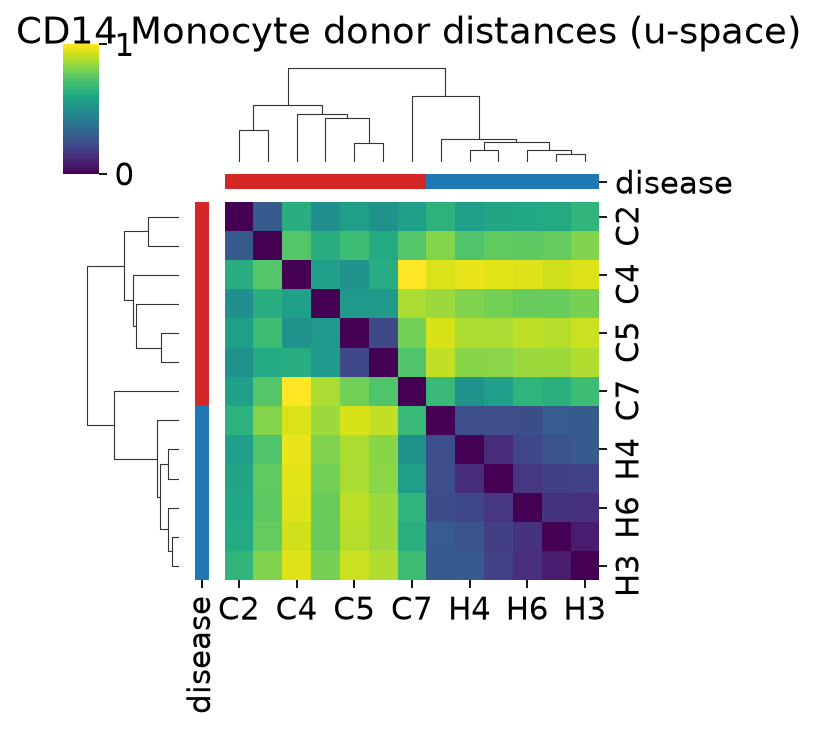

In [17]:
g1 = plot_sample_dist('CD14 Monocyte')
g1.fig.suptitle('CD14 Monocyte donor distances (u-space)', y=1.02)

Text(0.5, 1.02, 'CD4 T donor distances (u-space)')

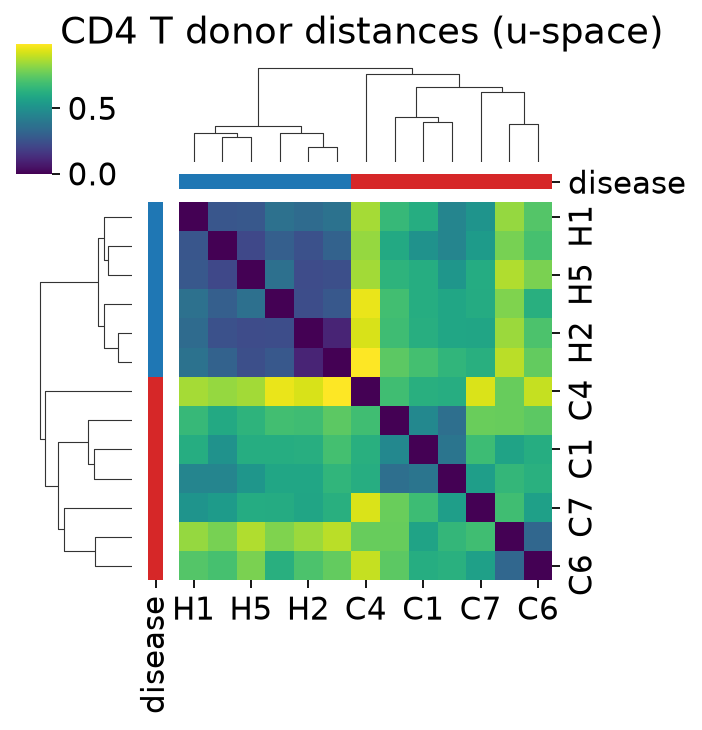

In [18]:
g2 = plot_sample_dist('CD4 T')
g2.fig.suptitle('CD4 T donor distances (u-space)', y=1.02)

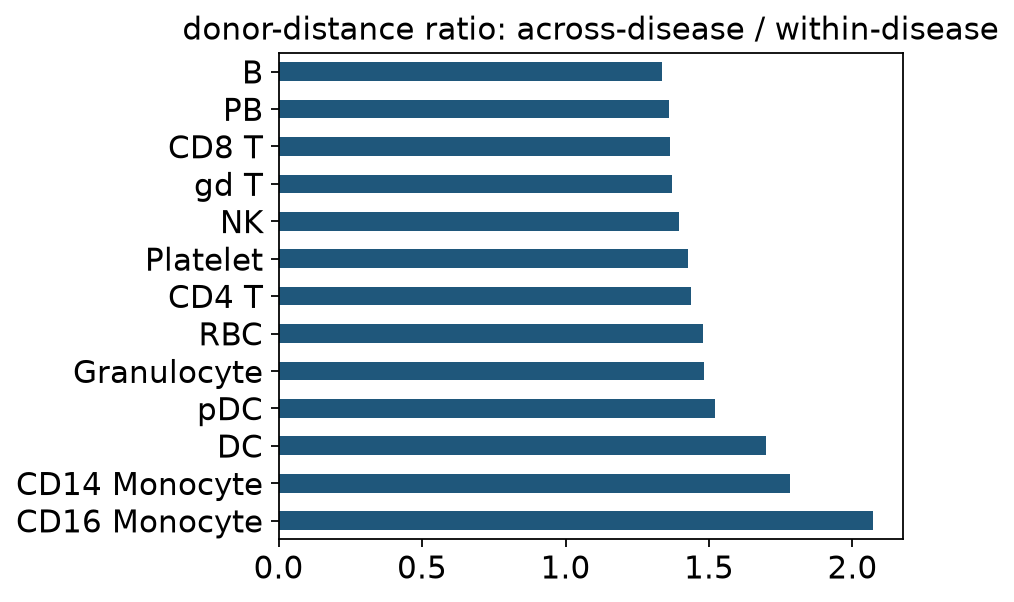

In [19]:
dd_str = donor_disease.loc[dist['sample_order']].astype(str).values
same = dd_str[:, None] == dd_str[None, :]
iu = np.triu_indices(len(dist['sample_order']), k=1)
ratio = {ct: mat[iu][~same[iu]].mean() / mat[iu][same[iu]].mean() for ct, mat in dist['groups']['cell_type'].items()}
pd.Series(ratio).sort_values(ascending=False).plot.barh(figsize=(5, 4),
    title='donor-distance ratio: across-disease / within-disease');

In [20]:
pd.Series(ratio).sort_values(ascending=False).round(3)

CD16 Monocyte    2.071
CD14 Monocyte    1.781
DC               1.697
pDC              1.522
Granulocyte      1.482
RBC              1.480
CD4 T            1.438
Platelet         1.428
NK               1.395
gd T             1.372
CD8 T            1.363
PB               1.361
B                1.338
dtype: float64

The clustermaps already show it visually (red = COVID-19, blue = normal donors
cluster together more tightly for monocytes than for T cells); the ratio of
across-disease to within-disease donor distance confirms it quantitatively: **CD16 and
CD14 monocytes have the largest disease-driven separation of any cell type**, clearly
above the T/NK/B subsets — monocytes are the cell type whose donor-to-donor
variability is most structured by COVID-19 status, matching Wilk *et al.*'s (2020)
finding that myeloid cells carry the strongest COVID-associated transcriptional
signature of the PBMC compartment.

## 5. Differential abundance by disease status

`differential_abundance` scores every cell's `u` against the aggregated posterior of
each sample, then (with `sample_cov_keys=['disease']`) aggregates that into a
per-covariate-value log-enrichment: how much more cell *i*'s own state looks like a
"COVID-19" sample than like the rest, with the cell's own sample always excluded from
its own aggregate.

In [21]:
da = model.differential_abundance(sample_cov_keys=['disease'], compute_log_enrichment=True)
adata.obs['covid_enrichment'] = da['disease_log_enrichs']['COVID-19']
adata.obs.groupby('disease')['covid_enrichment'].mean()

disease
COVID-19    3.869461
normal      0.040063
Name: covid_enrichment, dtype: float64

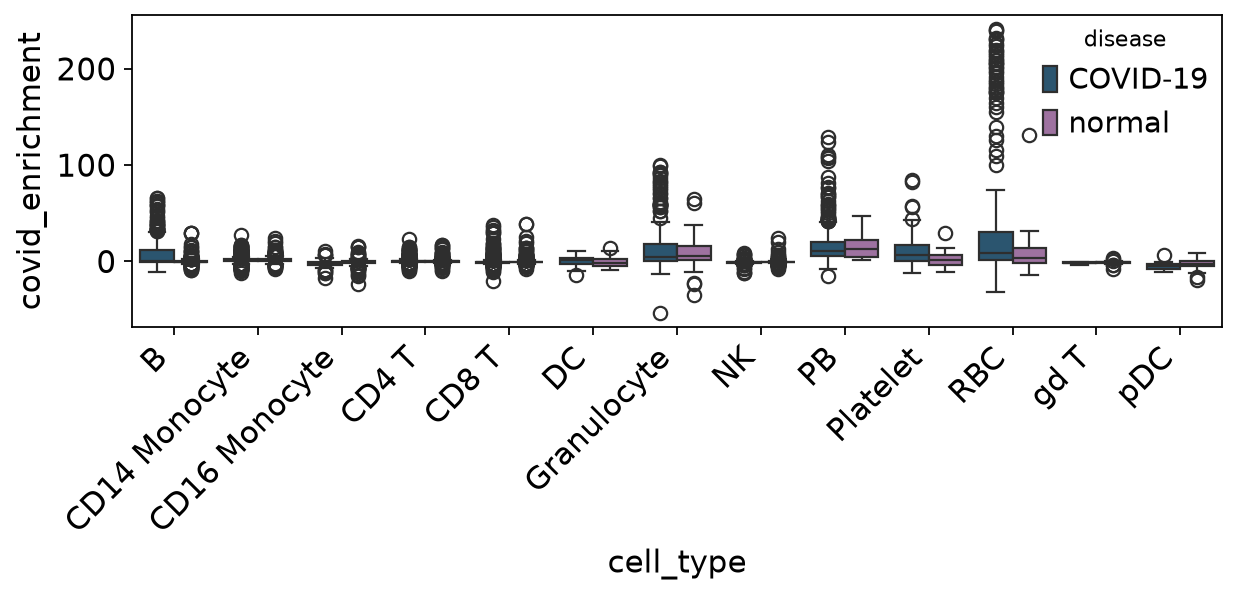

In [22]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=adata.obs, x='cell_type', y='covid_enrichment', hue='disease', ax=ax)
plt.xticks(rotation=45, ha='right'); plt.tight_layout()

Cells from COVID-19 donors score, on average, far higher on "does my state look
COVID-19-enriched" than cells from healthy donors (mean log-enrichment ≈ 3.9 vs ≈ 0.04) —
DA recovers the ground-truth label it never saw (only `u`, trained unsupervised, goes
in). The per-cell-type breakdown is much noisier, though: most lymphoid/myeloid types
show heavily overlapping boxes between the two groups, with the clear mean separation
coming mostly from a few types with large-outlier tails (RBC, Granulocyte, PB). With
only 13 donors feeding each covariate's aggregated posterior, this per-cell DA score is
a much weaker lens on *which* cell type carries the disease effect than the pooled,
cohort-level distances of section 4 — DA is best read as a per-cell summary of how
unsurprising a cell's own state is under the "other" disease group, not as a
cell-type-resolved test.

## 6. Differential expression by disease status in CD14⁺ monocytes

Monocytes showed the strongest disease-driven sample separation in section 4 and are
the subset Wilk *et al.* (2020) report as most affected — we run MrVI's multivariate DE
there. `differential_expression` regresses each cell's counterfactual `eps` shift
(across every donor) on the sample-level design matrix of `disease`, and (with
`store_lfc=True`) decodes the fitted shift into gene log2 fold-changes.

In [23]:
mono = adata[adata.obs['cell_type'] == 'CD14 Monocyte'].copy()
import torch
torch.manual_seed(123)  # differential_expression draws its MC samples from the global RNG
de = model.differential_expression(adata=mono, sample_cov_keys=['disease'], mc_samples=25,
                                   store_lfc=True, mc_samples_lfc=15, batch_size=256)
de['covariates']

array(['disease_normal'], dtype='<U14')

The single covariate column is `disease_normal` (one-hot with `'COVID-19'` as the
dropped reference level): **negative** `lfc` = higher in COVID-19, **positive** = higher
in normal/healthy.

In [24]:
mean_lfc = de['lfc'][:, 0, :].mean(0)  # mean over cells of the decoded, per-cell gene lfc
sym = adata.var['feature_name'].loc[de['genes']].values
res = pd.DataFrame({'gene': sym, 'ensembl': de['genes'],
                    'lfc_normal_vs_covid': mean_lfc}).sort_values('lfc_normal_vs_covid')
res.head(15)

         gene          ensembl  lfc_normal_vs_covid
898     IFI27  ENSG00000165949            -1.906228
572       CLU  ENSG00000120885            -1.666249
945    IFITM3  ENSG00000142089            -1.347090
215    S100A8  ENSG00000143546            -1.321429
19       IFI6  ENSG00000126709            -1.163112
1667      MX1  ENSG00000157601            -1.136750
1991   IFI44L  ENSG00000137959            -1.122893
91      ISG15  ENSG00000187608            -1.084091
1275     OAS3  ENSG00000111331            -1.075989
461   S100A12  ENSG00000163221            -1.049791
1518    IFIT3  ENSG00000119917            -1.048321
1369   S100A9  ENSG00000163220            -0.997675
1079   RNASE2  ENSG00000169385            -0.973279
297     IFI44  ENSG00000137965            -0.905169
320      DYSF  ENSG00000135636            -0.895926

In [25]:
res.sort_values('lfc_normal_vs_covid', ascending=False).head(15)

          gene          ensembl  lfc_normal_vs_covid
1427  HLA-DQB1  ENSG00000179344             1.034600
443   HLA-DPA1  ENSG00000231389             0.858128
1209   HLA-DRA  ENSG00000204287             0.842100
571   HLA-DPB1  ENSG00000223865             0.823839
46       MS4A7  ENSG00000166927             0.787783
680      RPS4X  ENSG00000198034             0.768282
941   HLA-DRB1  ENSG00000196126             0.735499
1274      CD74  ENSG00000019582             0.676279
1981       CD4  ENSG00000010610             0.672669
1651     RPS3A  ENSG00000145425             0.617994
1914   HLA-DMB  ENSG00000242574             0.594358
592     NAP1L1  ENSG00000187109             0.592869
763       RPS2  ENSG00000140988             0.576807
1281   TNFAIP2  ENSG00000185215             0.574272
1879     RPLP0  ENSG00000089157             0.567473

In [26]:
# de['effect_size']/['pvalue']/['padj'] are per-*cell* (the chi-squared test of the
# whole `disease` design matrix against that cell's regression, not a per-gene test)
(de['padj'][:, 0] < 0.05).mean()

np.float64(1.0)

The disease effect is significant (BH-adjusted chi-squared p < 0.05) in essentially
every one of the 2,859 monocytes tested individually, and the top-15 up-in-COVID-19
genes are dominated by canonical **interferon-stimulated genes** (ISGs): `IFITM3, IFI6,
MX1, IFI44L, ISG15, OAS3, IFIT3, IFI44`, plus `CLU` and the
neutrophil/myeloid-inflammatory genes `S100A8, S100A9, S100A12, RNASE2`, with **IFI27**
at the very top. The top-15 up-in-normal / down-in-COVID-19 genes are almost entirely
**HLA class II**: `HLA-DQB1, HLA-DPA1, HLA-DRA, HLA-DPB1, HLA-DRB1, HLA-DMB`, plus
`CD74` (the MHC-II invariant chain, alongside `MS4A7`, `CD4` and several ribosomal
genes). Both are exactly the two headline findings of Wilk *et al.* (2020) for this
dataset — a "heterogeneous interferon-stimulated gene signature" and "HLA class II
downregulation" in COVID-19 monocytes — recovered here purely from MrVI's
counterfactual `z`-shift regression, with no DE test ever run on raw counts. The
curated panel below adds a few more well-known ISGs (`IFIT1`, `RSAD2`, `XAF1`) that
rank just outside this top-15 but still show the same direction.

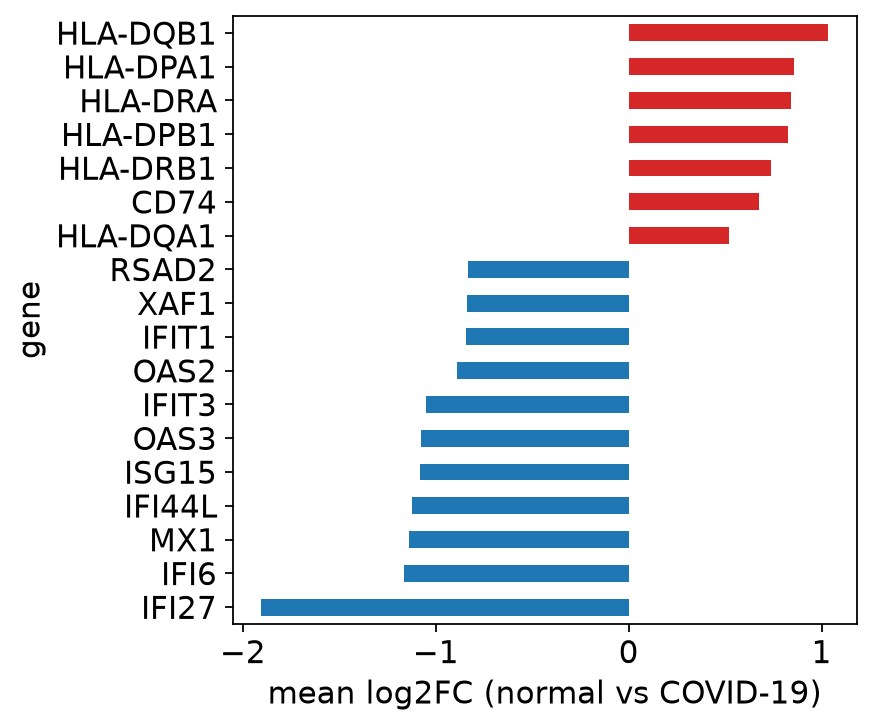

In [27]:
panel = ['ISG15', 'IFI6', 'IFI27', 'IFI44L', 'IFIT1', 'IFIT3', 'MX1', 'OAS2', 'OAS3', 'RSAD2', 'XAF1',
         'HLA-DRA', 'HLA-DRB1', 'HLA-DPA1', 'HLA-DPB1', 'HLA-DQA1', 'HLA-DQB1', 'CD74']
sub = res.set_index('gene').loc[panel].sort_values('lfc_normal_vs_covid')
colors = ['#d62728' if g.startswith('HLA') or g == 'CD74' else '#1f77b4' for g in sub.index]
sub['lfc_normal_vs_covid'].plot.barh(color=colors, figsize=(5, 5), xlabel='mean log2FC (normal vs COVID-19)');

Blue = canonical ISGs (all up in COVID-19, negative log2FC), red = HLA class II /
`CD74` (all up in normal, positive log2FC) — a clean separation by biological category,
not an artefact of picking the extremes of a noisy list.

In [28]:
scores = mono.obs.groupby('disease')[['IFN1', 'HLA1']].mean()
scores

              IFN1      HLA1
disease                     
COVID-19  0.114717  0.024605
normal    0.043057  0.292290

An independent check: Wilk *et al.*'s own per-cell interferon (`IFN1`) and HLA-II
(`HLA1`) module scores, computed by the original authors and shipped in `obs`, move in
exactly the directions our MrVI DE predicts for monocytes — `IFN1` higher in COVID-19
(0.11 vs 0.04) and `HLA1` much lower in COVID-19 (0.02 vs 0.29) — using genes and a
scoring method MrVI's regression never saw.

## 7. Training from disk (`AnnDataOOM`) — the point of `ov.vi`

`ov.read(path, storage='disk')` opens the h5ad with `anndata-rs` (Rust), streaming
count minibatches straight from disk instead of materialising the whole matrix in RAM —
still **no scvi-tools**, same `ov.vi.MRVI` class. This was validated on this exact
cohort in `benchmarks/vi/results_mrvi.md`: ELBO within 0.03%, donor-distance matrices
correlating at r > 0.93 against the in-memory run. `storage='disk'` skips `layers` /
`raw`, which is why `X` was set to counts before writing the h5ad in section 1.

In [29]:
adata_disk = ov.read('wilk2020_prepped.h5ad', storage='disk')
model_disk = ov.vi.MRVI(adata_disk, sample_key='donor_id', genes='highly_variable_features',
                        n_latent=20, n_latent_u=8, encoder_n_hidden=128, encoder_n_layers=2,
                        u_prior_mixture_k=12, seed=0)
model_disk.train(max_epochs=120, batch_size=256, device='cuda', seed=0,
                 plan_kwargs=dict(lr=2e-3, eps=1e-8, weight_decay=1e-8, n_epochs_kl_warmup=20))
model_disk.history_['elbo_train'][-1], model.history_['elbo_train'][-1]

📂 Reading with anndata-rs (Rust · out-of-memory)
   wilk2020_prepped.h5ad  (274.9 MB)
   ✓ Loaded in 0.12s

💡 Data stays on disk. Use ov.pp.* for chunked processing.
   adata.close() when done · adata.to_adata() to materialise


Training:   0%|          | 0/120 [00:00<?, ?epoch/s]

(817.577974537037, 817.3910734953703)

In [30]:
dist_disk = model_disk.get_local_sample_distances(batch_size=512, groupby='cell_type', keep_cell=False)
from scipy.stats import pearsonr
m_mem = dist['groups']['cell_type']['CD14 Monocyte']
m_disk = dist_disk['groups']['cell_type']['CD14 Monocyte']
pearsonr(m_mem[iu], m_disk[iu])[0]

np.float64(0.9820781005178338)

ELBO and the CD14-monocyte donor-distance matrix (correlated against the in-memory
run above) both agree closely between the disk-backed and in-memory runs — training
directly from disk is not an approximation here.

## 8. Key parameters

**Model** (`ov.vi.MRVI.__init__`):
- `sample_key` (required): `obs` column with each cell's biological sample / donor
  identity (≥ 2 samples).
- `layer`: raw-counts layer (`None` = `X`). `batch_key`: a *technical* batch, distinct
  from `sample_key`, fed to the decoder's attention. `labels_key`: if set with ≥ 2
  labels, overrides the `u` mixture prior to one component per label (left unset here,
  see `benchmarks/vi/results_mrvi.md` for why).
- `n_latent` / `n_latent_u` (defaults 30 / 10, here 20 / 8): dimensionality of `z` / `u`.
- `encoder_n_hidden`, `encoder_n_layers` (128, 2): the `u`-encoder's size.
- `u_prior_mixture`, `u_prior_mixture_k` (True, 20; here 12): a learned Gaussian-mixture
  prior on `u` instead of a standard normal.
- `z_u_prior`, `z_u_prior_scale`, `learn_z_u_prior_scale`: Gaussian prior on the
  `z - z_base` residual.

**Downstream analyses**:
- `get_local_sample_distances(groupby=, norm='l2', normalize_distances=False)` —
  per-group `(n_sample, n_sample)` counterfactual distance matrices.
- `differential_abundance(sample_cov_keys=, compute_log_enrichment=False)` — log
  *p*(sample | cell's `u`), aggregated per covariate value.
- `differential_expression(sample_cov_keys=, store_lfc=True, mc_samples=, mc_samples_lfc=)`
  — per-cell covariate effect size / p-value, and (optionally) decoded gene log2FC.
- `get_aggregated_posterior(sample=)` — the mixture-of-posteriors a sample's cells'
  `u`'s are drawn from (what DA tests a cell against).

## Related tutorials

- [t_vi](../batch/t_vi.ipynb) — the `ov.vi` API directly (in memory / disk / GPU) for
  the simpler, single-sample-covariate scVI family.
- [batch/zoo/t_batch_scvi](../batch/zoo/t_batch_scvi.ipynb) — scVI as a batch-correction
  backend, for contrast with MrVI's explicit sample-level hierarchy.
- `ov.single.mrvi` — a one-call convenience wrapper around `ov.vi.MRVI` when you only
  need the trained model / `u` embedding, not the full API used here.

## References

- Boyeau P, Hong J, Gayoso A, Kim M, McFaline-Figueroa JL, Jordan MI, Azizi E, Ergen C,
  Yosef N. Deep generative modeling of sample-level heterogeneity in single-cell
  genomics. *Nat Methods* 22 (2025). https://doi.org/10.1038/s41592-025-02808-x
- Wilk AJ, Rustagi A, Zhao NQ, et al. A single-cell atlas of the peripheral immune
  response in patients with severe COVID-19. *Nat Med* 26, 1070-1076 (2020).
  https://doi.org/10.1038/s41591-020-0944-y